In [1]:
import pandas as ps
import numpy as nm
import matplotlib.pyplot as plt

In [2]:

df = ps.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
df.info()
print(df.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome    

In [7]:
x = df.iloc[:, 0:8].values
print(x)

[[  6.    148.     72.    ...  33.6     0.627  50.   ]
 [  1.     85.     66.    ...  26.6     0.351  31.   ]
 [  8.    183.     64.    ...  23.3     0.672  32.   ]
 ...
 [  5.    121.     72.    ...  26.2     0.245  30.   ]
 [  1.    126.     60.    ...  30.1     0.349  47.   ]
 [  1.     93.     70.    ...  30.4     0.315  23.   ]]


In [8]:
y = df.iloc[:, 8].values  
print(y)

[1 0 1 0 1 0 1 0 1 1 0 1 0 1 1 1 1 1 0 1 0 0 1 1 1 1 1 0 0 0 0 1 0 0 0 0 0
 1 1 1 0 0 0 1 0 1 0 0 1 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 1 0 1 0 0 0 1 0 1 0
 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 1
 1 0 0 1 1 1 0 0 0 1 0 0 0 1 1 0 0 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 0 1 0 1 1 0 0 0 1 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 1 0 1 0 1 0 0 0 0 0
 1 1 1 1 1 0 0 1 1 0 1 0 1 1 1 0 0 0 0 0 0 1 1 0 1 0 0 0 1 1 1 1 0 1 1 1 1
 0 0 0 0 0 1 0 0 1 1 0 0 0 1 1 1 1 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0
 1 0 1 0 0 1 0 1 0 0 1 1 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 0 1 0 0 0 1 1 1 0 0
 1 0 1 0 1 1 0 1 0 0 1 0 1 1 0 0 1 0 1 0 0 1 0 1 0 1 1 1 0 0 1 0 1 0 0 0 1
 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 1 0 1 1 0 0 1 0 0 1 0 0 1
 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1 1 1 0 0 1 0 0 1 0 0 1 0 1 1 0 1 0 1 0 1
 0 1 1 0 0 0 0 1 1 0 1 0 1 0 0 0 0 1 1 0 1 0 1 0 0 0 0 0 1 0 0 0 0 1 0 0 1
 1 1 0 0 1 0 0 1 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1
 0 0 0 1 1 0 0 0 0 0 0 0 

In [9]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(
    x,y,
    test_size=0.2,
    random_state=45
)

In [10]:
from sklearn.preprocessing import StandardScaler
sc_x = StandardScaler()
x_train = sc_x.fit_transform(x_train) 
x_test=sc_x.transform(x_test)

In [11]:

from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier(criterion='gini', random_state=0)

classifier.fit(x_train,y_train)


y_pred = classifier.predict(x_test) 

In [12]:
 print("Actual: ",y_test)
 print("Predicted: ",y_pred)

Actual:  [1 0 1 0 0 0 1 0 1 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0 0 0
 0 1 0 1 0 0 1 1 1 1 0 0 0 0 1 0 1 0 0 0 0 1 1 1 1 0 0 0 1 0 1 1 0 1 1 0 0
 0 0 1 0 0 0 0 1 1 0 1 0 1 1 0 0 0 1 0 0 0 0 1 1 1 0 1 1 0 1 0 0 0 0 0 0 1
 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0
 0 0 0 1 1 0]
Predicted:  [1 0 1 0 0 0 1 0 1 0 0 0 0 1 1 0 1 0 1 0 1 1 1 0 0 1 0 1 0 0 0 1 0 0 0 0 1
 0 0 0 0 1 0 1 1 0 0 1 0 0 1 1 1 0 0 1 0 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1 1 1 1 0 0 1 1 1 1 1 0 1 0 1 1 1
 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0
 1 1 0 0 1 0]




True Pos 77
True Neg 27
False Pos 26
False Neg 24

Accuracy -  65.5844155844156 %
              precision    recall  f1-score   support

           0       0.75      0.74      0.74       104
           1       0.47      0.48      0.48        50

    accuracy                           0.66       154
   macro avg       0.61      0.61      0.61       154
weighted avg       0.66      0.66      0.66       154



[Text(0.5746951219512195, 0.9642857142857143, 'x[1] <= 0.709\ngini = 0.458\nsamples = 614\nvalue = [396.0, 218.0]'),
 Text(0.25914634146341464, 0.8928571428571429, 'x[5] <= -0.571\ngini = 0.365\nsamples = 474\nvalue = [360, 114]'),
 Text(0.4169207317073171, 0.9285714285714286, 'True  '),
 Text(0.06829268292682927, 0.8214285714285714, 'x[1] <= 0.227\ngini = 0.067\nsamples = 144\nvalue = [139, 5]'),
 Text(0.03902439024390244, 0.75, 'x[5] <= -0.621\ngini = 0.032\nsamples = 123\nvalue = [121, 2]'),
 Text(0.01951219512195122, 0.6785714285714286, 'x[0] <= 1.642\ngini = 0.017\nsamples = 119\nvalue = [118, 1]'),
 Text(0.00975609756097561, 0.6071428571428571, 'gini = 0.0\nsamples = 115\nvalue = [115, 0]'),
 Text(0.02926829268292683, 0.6071428571428571, 'x[7] <= -0.105\ngini = 0.375\nsamples = 4\nvalue = [3, 1]'),
 Text(0.01951219512195122, 0.5357142857142857, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.03902439024390244, 0.5357142857142857, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 T

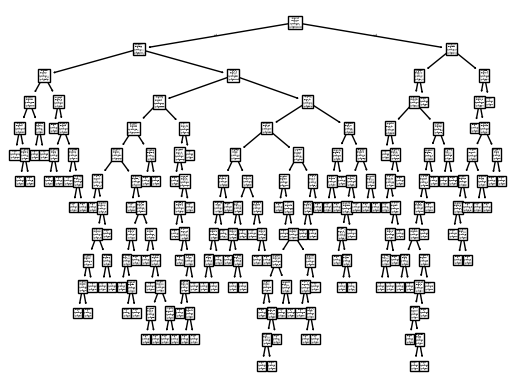

In [13]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

print("\n\nTrue Pos", cm[0][0])
print("True Neg", cm[0][1])
print("False Pos", cm[1][0])
print("False Neg", cm[1][1])

accuracy = (cm[0][0]  + cm[1][1]) / (cm[0][0]  + cm[1][1] + cm[1][0] + cm[0][1])
print("\nAccuracy - ", accuracy * 100, "%")

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

from sklearn import tree
tree.plot_tree(classifier)